# Notebook 1 — Algorithm Comparison, Existing Models vs Proposed Model, and Evaluation Metrics

**Project:** Early warning of low dissolved oxygen (DO) in rivers using multimodal data
**Course:** 21CSC305P Machine Learning — SRM Institute of Science and Technology, Ramapuram

---

### What this notebook shows

| Section | Content |
|---|---|
| 1 | Dataset and the evaluation protocol (train 2023 · validate 2024 · test 2025) |
| 2 | The algorithms compared — existing approaches and the proposed model |
| 3 | Evaluation metrics, with their formulas |
| 4 | Regression comparison (R², RMSE, MAE, NSE, skill) at every horizon |
| 5 | Classification comparison (accuracy, precision, recall, F1, ROC-AUC) |
| 6 | Existing model vs proposed model — head to head |
| 7 | Confusion matrices and ROC curves |
| 8 | Statistical significance (bootstrap confidence intervals) |
| 9 | Early-warning performance: onset recall, false alarms, lead time |
| 10 | Multimodal ablation: what each data source contributes |
| 11 | Generalisation to a second unseen year (2026) |
| 12 | Conclusion |

**Every number below is recomputed in this notebook** from the hour-by-hour 2025 forecasts that each model
produced (`results/test/pred_<model>_h<h>.parquet`), using the project's own metric code
(`src/evaluation/metrics.py`). Nothing is typed in by hand. Model training itself is shown in **Notebook 2**.

## 0. Setup

In [1]:
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Work from the project root (the folder that holds config.yaml), wherever the notebook is opened from
ROOT = Path.cwd()
while not (ROOT / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.metrics import roc_curve, auc

from src.config import load_config
from src.evaluation.metrics import (regression_metrics, classification_metrics,
                                    early_warning_metrics, danger_zone_rmse)

CFG = load_config()
HORIZONS = CFG["horizons"]                       # [6, 12, 24, 48] hours ahead
CLASS_NAMES = CFG["target"]["class_names"]       # Low / Medium / Good
LOW, GOOD = CFG["target"]["thresholds"]["low"], CFG["target"]["thresholds"]["good"]
TEST_DIR = ROOT / "results" / "test"
FIG_DIR = ROOT / "results" / "notebook_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project root :", ROOT)
print("Horizons     :", HORIZONS, "hours")
print(f"Classes      : Low < {LOW} mg/L <= Medium <= {GOOD} mg/L < Good")

Project root : /home/claude/v2
Horizons     : [6, 12, 24, 48] hours
Classes      : Low < 5.0 mg/L <= Medium <= 7.0 mg/L < Good


## 1. Dataset and evaluation protocol

* **30 USGS river stations** in 15 US states, **hourly** data from 2023-01-01 to 2025-12-31.
* **Three data sources (multimodal):**
  * **Water-quality sensors (USGS):** dissolved oxygen, water temperature, conductivity, pH, turbidity, discharge
  * **Weather (ERA5 reanalysis):** air temperature, humidity, rain, pressure, wind, radiation, soil moisture, evapotranspiration
  * **Air quality (CAMS):** PM10, PM2.5, CO, NO₂, SO₂, ozone, aerosol optical depth, dust
* **211 engineered features** per hour (lags, rolling statistics, rates of change, weather and air features, time, station).
* **Two tasks**, each at 4 forecast horizons (6, 12, 24, 48 h ahead):
  * **Regression** — predict the DO value in mg/L
  * **Classification** — predict the class: **Low** (< 5 mg/L, harmful to fish), **Medium** (5–7), **Good** (> 7)

**Chronological split — no shuffling, no leakage:**

| Year | Role |
|---|---|
| 2023 | Training |
| 2024 | Validation — every hyperparameter, the ensemble and the warning threshold were chosen here |
| 2025 | **Test** — frozen system scored **once** (settings and file hashes committed in `FROZEN.md` before the test) |

In [2]:
DO = CFG["target"]["column"]
rows = []
for split, year in [("train", 2023), ("val", 2024), ("test", 2025)]:
    df = pd.read_parquet(ROOT / CFG["paths"][split], columns=["station", "time", DO, "y_cls_24"])
    cls = df["y_cls_24"].astype("float64")
    rows.append({"split": split, "year": year, "rows (station-hours)": len(df),
                 "stations": df["station"].nunique(),
                 "from": df["time"].min().date(), "to": df["time"].max().date(),
                 "mean DO (mg/L)": df[DO].mean(),
                 "% Low": (cls == 0).mean() * 100, "% Medium": (cls == 1).mean() * 100,
                 "% Good": (cls == 2).mean() * 100})
splits = pd.DataFrame(rows).set_index("split")
with open(ROOT / CFG["paths"]["feature_groups"]) as f:
    groups = json.load(f)
display(splits)
print("Feature groups:", {g: len(groups[g]) for g in ["water", "weather", "air", "time", "station"]},
      "| total =", sum(len(groups[g]) for g in ["water", "weather", "air", "time", "station"]))

,year,rows (station-hours),stations,from,to,mean DO (mg/L),% Low,% Medium,% Good
split,,,,,,,,,
train,2023,255233,30,2023-01-04,2023-12-29,7.5495,19.1852,27.3315,52.7788
val,2024,253603,30,2024-01-01,2024-12-29,7.5549,20.3909,24.1074,54.7572
test,2025,253954,30,2025-01-01,2025-12-31,7.6452,19.5528,24.7218,54.8265


Feature groups: {'water': 148, 'weather': 39, 'air': 16, 'time': 5, 'station': 3} | total = 211


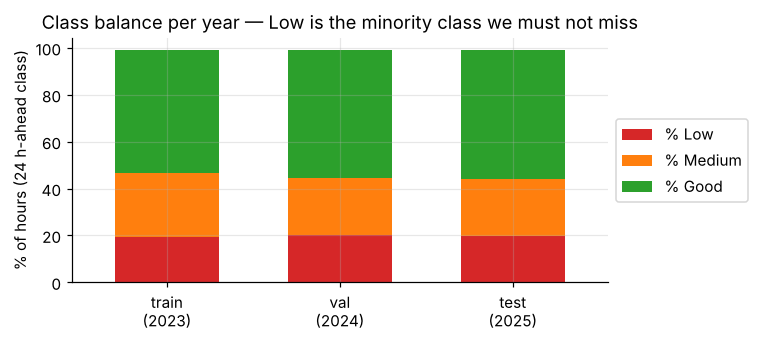

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
splits[["% Low", "% Medium", "% Good"]].plot(kind="bar", stacked=True, ax=ax,
                                             color=["#d62728", "#ff7f0e", "#2ca02c"], width=.6)
ax.set_ylabel("% of hours (24 h-ahead class)"); ax.set_xlabel("")
ax.set_xticklabels([f"{s}\n({y})" for s, y in zip(splits.index, splits["year"])], rotation=0)
ax.set_title("Class balance per year — Low is the minority class we must not miss")
ax.legend(loc="center left", bbox_to_anchor=(1, .5))
plt.tight_layout(); plt.savefig(FIG_DIR / "nb1_class_balance.png", bbox_inches="tight"); plt.show()

## 2. Algorithms compared

**Existing approaches** — what is normally used, and what any new model has to beat:

| # | Algorithm | Type | Why it is here |
|---|---|---|---|
| E1 | **Persistence** ("DO will stay what it is now") | Naive baseline | The operational default: read the sensor. A model that cannot beat it is useless. |
| E2 | **Linear / Logistic Regression** | Classical statistical | Standard linear baseline used in water-quality forecasting. |
| E3 | **LightGBM** (single model) | Gradient-boosted trees | The strongest existing single algorithm on this data — the *best existing model*. |

**The five base models trained in this project** (3 Machine Learning + 2 Deep Learning, see Notebook 2):

| # | Model | Family | Key idea |
|---|---|---|---|
| M1 | Random Forest | ML — bagging | 300 decorrelated trees, median imputation, balanced class weights |
| M2 | XGBoost | ML — boosting | Second-order gradient boosting, native missing-value handling |
| M3 | LightGBM | ML — boosting | Leaf-wise boosting, station as a categorical feature |
| M4 | BiLSTM | DL — recurrent | Bidirectional LSTM over the last 72 h of 29 raw channels + engineered-feature branch |
| M5 | CNN-LSTM | DL — conv + recurrent | 1-D convolutions detect short patterns (sudden drops), LSTM reads the sequence |

**Proposed model (my model):**

> **Stacking ensemble of the 5 models + a threshold-based early-warning rule**
> 1. Each of the 5 models forecasts DO (regression) and P(Low/Medium/Good) (classification).
> 2. A **meta-learner** combines them — Ridge regression on the 5 DO forecasts; multinomial logistic regression on the 15 class probabilities — fitted on the 2024 validation year (data the base models never trained on).
> 3. **Warning rule:** instead of "pick the most likely class" (argmax), raise a Low warning whenever **P(Low) ≥ τ**, where τ was chosen on 2024 to catch the most onsets with a false-alarm rate ≤ 1.8 % (promise: ≤ 2 %).

A **simple average** of the 5 models is also shown, to prove that the *learned* combination is what matters.
Two further combiners built in this project — an adaptive threshold-aware ensemble (ATAE) and a context-aware ensemble (CAE) —
were tested on the 2024 validation year and **rejected by a decision rule written before their results were known**
(see `reports/step6_ensemble_report.md` and `reports/step7_cae_report.md`), so they are not part of the final system.

In [4]:
METHODS = {   # key: (display name, group)
    "persistence":    ("Persistence",               "Existing (naive)"),
    "linear":         ("Linear / Logistic Reg.",    "Existing (classical)"),
    "random_forest":  ("Random Forest",             "Base model (ML)"),
    "xgboost":        ("XGBoost",                   "Base model (ML)"),
    "lightgbm":       ("LightGBM",                  "Base model (ML) = best existing"),
    "bilstm":         ("BiLSTM",                    "Base model (DL)"),
    "cnn_lstm":       ("CNN-LSTM",                  "Base model (DL)"),
    "simple_average": ("Simple average of 5",       "Naive ensemble"),
    "stacking":       ("Stacking + warning rule",   "PROPOSED"),
}
NAME = {k: v[0] for k, v in METHODS.items()}
PROPOSED, BEST_EXISTING = "stacking", "lightgbm"
COLOR = {"persistence": "#9e9e9e", "linear": "#bdbdbd", "random_forest": "#6baed6",
         "xgboost": "#4292c6", "lightgbm": "#2171b5", "bilstm": "#9e9ac8",
         "cnn_lstm": "#756bb1", "simple_average": "#fdae6b", "stacking": "#d94801"}

# Load every 2025 forecast of every model at every horizon
PRED = {}
for m in METHODS:
    for h in HORIZONS:
        PRED[(m, h)] = pd.read_parquet(TEST_DIR / f"pred_{m}_h{h}.parquet")

# All models must forecast exactly the same station-hours, otherwise the comparison is unfair
for h in HORIZONS:
    ref = PRED[("persistence", h)][["station", "time"]]
    for m in METHODS:
        assert PRED[(m, h)][["station", "time"]].equals(ref), (m, h)
print(f"Loaded {len(PRED)} forecast files; every model forecasts the same "
      f"{len(ref):,} station-hours of 2025 at each horizon.")
display(PRED[("stacking", 24)].head())

Loaded 36 forecast files; every model forecasts the same 253,954 station-hours of 2025 at each horizon.


,station,time,y_true_reg,y_true_cls,class_now,pred_reg,pred_argmax,pred_warn,proba_Low,proba_Medium,proba_Good
0,01302020,2025-01-01 00:00:00,10.3333,2.0,2.0,10.2620,2,2,0.0006,0.0221,0.9773
1,01302020,2025-01-01 01:00:00,10.2000,2.0,2.0,10.1780,2,2,0.0006,0.0221,0.9773
2,01302020,2025-01-01 02:00:00,10.2000,2.0,2.0,10.2524,2,2,0.0006,0.0221,0.9773
3,01302020,2025-01-01 03:00:00,10.1500,2.0,2.0,10.2526,2,2,0.0006,0.0221,0.9773
4,01302020,2025-01-01 04:00:00,10.1500,2.0,2.0,10.2091,2,2,0.0006,0.0221,0.9773


## 3. Evaluation metrics

**Regression** (y = observed DO, ŷ = forecast, n = scored hours):

| Metric | Formula | Meaning |
|---|---|---|
| **R²** | $1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2}$ | Share of variance explained (1 = perfect) |
| **RMSE** | $\sqrt{\frac1n\sum(y-\hat y)^2}$ | Typical error in mg/L; penalises large errors |
| **MAE** | $\frac1n\sum\lvert y-\hat y\rvert$ | Average absolute error in mg/L |
| **NSE** | Nash–Sutcliffe efficiency (same formula as R²) | Standard score in hydrology |
| **Skill vs persistence** | $1-\frac{RMSE_{model}}{RMSE_{persistence}}$ | > 0 means better than "no change" |
| **Danger-zone RMSE** | RMSE on hours with 3 ≤ y ≤ 7 mg/L | Accuracy where the river crosses into trouble |

**Classification** (Low / Medium / Good; TP, FP, FN per class):

| Metric | Formula | Meaning |
|---|---|---|
| **Accuracy** | $\frac{\text{correct}}{n}$ | Overall share of correct classes |
| **Balanced accuracy** | mean of per-class recall | Accuracy that is not fooled by the large Good class |
| **Precision** | $\frac{TP}{TP+FP}$ | Of the hours predicted as a class, how many were right |
| **Recall** | $\frac{TP}{TP+FN}$ | Of the hours truly in a class, how many were found |
| **F1 (macro)** | mean over classes of $\frac{2PR}{P+R}$ | Balance of precision and recall, each class weighted equally |
| **ROC-AUC** | area under the ROC curve (one-vs-rest, macro) | Ranking quality of the probabilities |

**Early-warning metrics** (what the project exists for):

| Metric | Definition |
|---|---|
| **Low recall** | Share of all truly-Low hours predicted Low |
| **Onset recall** | Of the hours where water is **safe now but Low at t+h**, the share predicted Low — the hours a sensor alone cannot warn about |
| **False-alarm rate** | Of the hours that are safe now and **stay** safe, the share wrongly warned Low (promise: ≤ 2 %) |
| **Lead time** | Hours between the first warning and the start of a real low-DO event |

Persistence scores **0 onset recall by definition** — it never predicts a change.

## 4. Regression comparison — predicting the DO value

In [5]:
reg_rows = []
for h in HORIZONS:
    persist = PRED[("persistence", h)]["pred_reg"].to_numpy()
    for m in METHODS:
        d = PRED[(m, h)]
        r = regression_metrics(d["y_true_reg"], d["pred_reg"], persist)
        r["danger_rmse"] = danger_zone_rmse(d["y_true_reg"], d["pred_reg"], 3.0, 7.0)
        reg_rows.append({"key": m, "model": NAME[m], "group": METHODS[m][1], "horizon": h, **r})
REG = pd.DataFrame(reg_rows)

cols = ["model", "group", "r2", "rmse", "mae", "nse", "skill_vs_persistence", "danger_rmse"]
t24 = REG[REG.horizon == 24][cols].set_index("model")
display(Markdown("### Regression, 24 hours ahead, test year 2025 (lower RMSE / MAE is better)"))
display(t24.style.format({c: "{:.4f}" for c in cols[2:]})
        .highlight_min(subset=["rmse", "mae", "danger_rmse"], color="#ffd8b1")
        .highlight_max(subset=["r2", "nse", "skill_vs_persistence"], color="#ffd8b1"))

### Regression, 24 hours ahead, test year 2025 (lower RMSE / MAE is better)

,group,r2,rmse,mae,nse,skill_vs_persistence,danger_rmse
model,,,,,,,
Persistence,Existing (naive),0.9375,0.7553,0.4569,0.9375,0.0000,0.7263
Linear / Logistic Reg.,Existing (classical),0.9471,0.6950,0.4294,0.9471,0.0798,0.6553
Random Forest,Base model (ML),0.9475,0.6924,0.4189,0.9475,0.0833,0.6339
XGBoost,Base model (ML),0.9471,0.6951,0.4207,0.9471,0.0797,0.6297
LightGBM,Base model (ML) = best existing,0.9490,0.6822,0.4158,0.9490,0.0968,0.6323
BiLSTM,Base model (DL),0.9480,0.6887,0.4197,0.9480,0.0882,0.6537
CNN-LSTM,Base model (DL),0.9484,0.6860,0.4159,0.9484,0.0918,0.6535
Simple average of 5,Naive ensemble,0.9503,0.6737,0.4086,0.9503,0.1081,0.6311
Stacking + warning rule,PROPOSED,0.9505,0.6718,0.4074,0.9505,0.1105,0.6339


In [6]:
display(Markdown("### RMSE (mg/L) at every horizon"))
piv = REG.pivot(index="model", columns="horizon", values="rmse").loc[[NAME[m] for m in METHODS]]
piv.columns = [f"RMSE {h} h" for h in piv.columns]
r2p = REG.pivot(index="model", columns="horizon", values="r2").loc[[NAME[m] for m in METHODS]]
r2p.columns = [f"R² {h} h" for h in r2p.columns]
display(pd.concat([piv, r2p], axis=1).style.format("{:.4f}").highlight_min(subset=piv.columns, color="#ffd8b1")
        .highlight_max(subset=r2p.columns, color="#ffd8b1"))

### RMSE (mg/L) at every horizon

,RMSE 6 h,RMSE 12 h,RMSE 24 h,RMSE 48 h,R² 6 h,R² 12 h,R² 24 h,R² 48 h
model,,,,,,,,
Persistence,1.3437,1.5320,0.7553,1.0074,0.8023,0.7429,0.9375,0.8888
Linear / Logistic Reg.,0.6091,0.6523,0.6950,0.8890,0.9594,0.9534,0.9471,0.9134
Random Forest,0.5888,0.6339,0.6924,0.8841,0.9621,0.9560,0.9475,0.9144
XGBoost,0.5386,0.6147,0.6951,0.8779,0.9682,0.9586,0.9471,0.9156
LightGBM,0.5293,0.6034,0.6822,0.8752,0.9693,0.9601,0.9490,0.9161
BiLSTM,0.5966,0.6477,0.6887,0.8778,0.9610,0.9540,0.9480,0.9156
CNN-LSTM,0.5868,0.6424,0.6860,0.8729,0.9623,0.9548,0.9484,0.9165
Simple average of 5,0.5286,0.5936,0.6737,0.8544,0.9694,0.9614,0.9503,0.9200
Stacking + warning rule,0.5144,0.5882,0.6718,0.8535,0.9710,0.9621,0.9505,0.9202


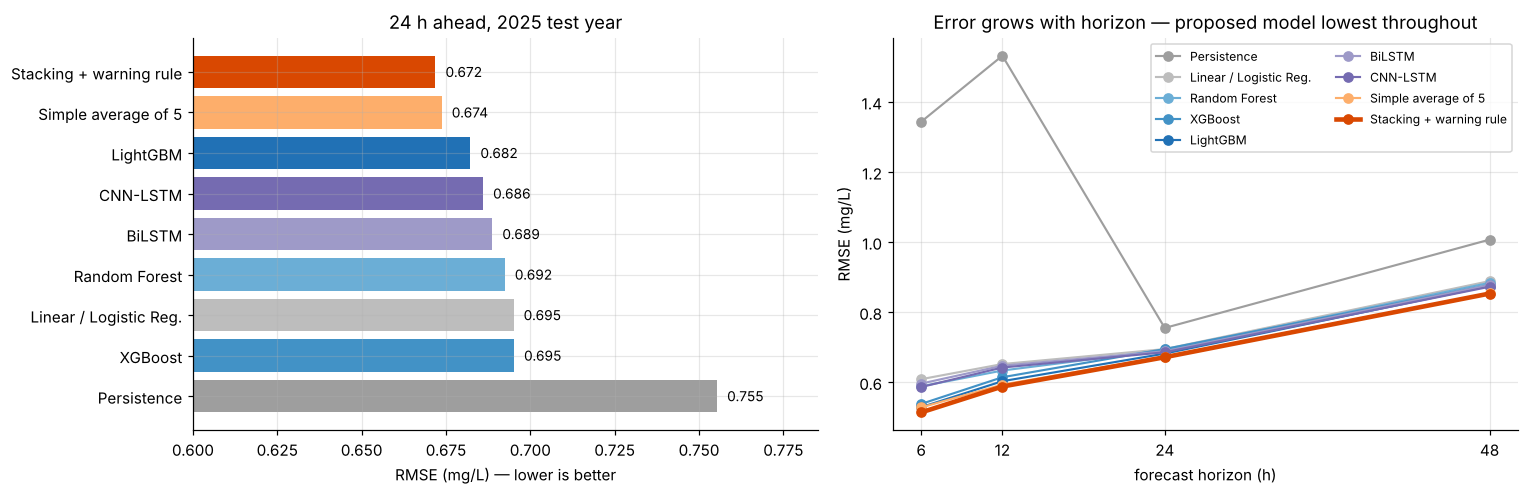

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
d = REG[REG.horizon == 24].sort_values("rmse", ascending=False)
axes[0].barh(d["model"], d["rmse"], color=[COLOR[k] for k in d["key"]])
for y, v in enumerate(d["rmse"]):
    axes[0].text(v + .003, y, f"{v:.3f}", va="center", fontsize=9)
axes[0].set_xlim(.6, d["rmse"].max() + .03)
axes[0].set_xlabel("RMSE (mg/L) — lower is better"); axes[0].set_title("24 h ahead, 2025 test year")

for m in METHODS:
    s = REG[REG.key == m]
    axes[1].plot(s["horizon"], s["rmse"], "-o", color=COLOR[m], label=NAME[m],
                 lw=3 if m == PROPOSED else 1.4, zorder=3 if m == PROPOSED else 2)
axes[1].set_xticks(HORIZONS); axes[1].set_xlabel("forecast horizon (h)")
axes[1].set_ylabel("RMSE (mg/L)"); axes[1].set_title("Error grows with horizon — proposed model lowest throughout")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(FIG_DIR / "nb1_rmse_comparison.png", bbox_inches="tight"); plt.show()

*Persistence looks unusually good at 24 h (and worse at 6 h / 12 h) because DO follows a daily cycle:
the value 24 h later is close to the value now. Even so, every learned model beats it at every horizon.*

A one-month example — what the forecasts look like next to the real sensor:

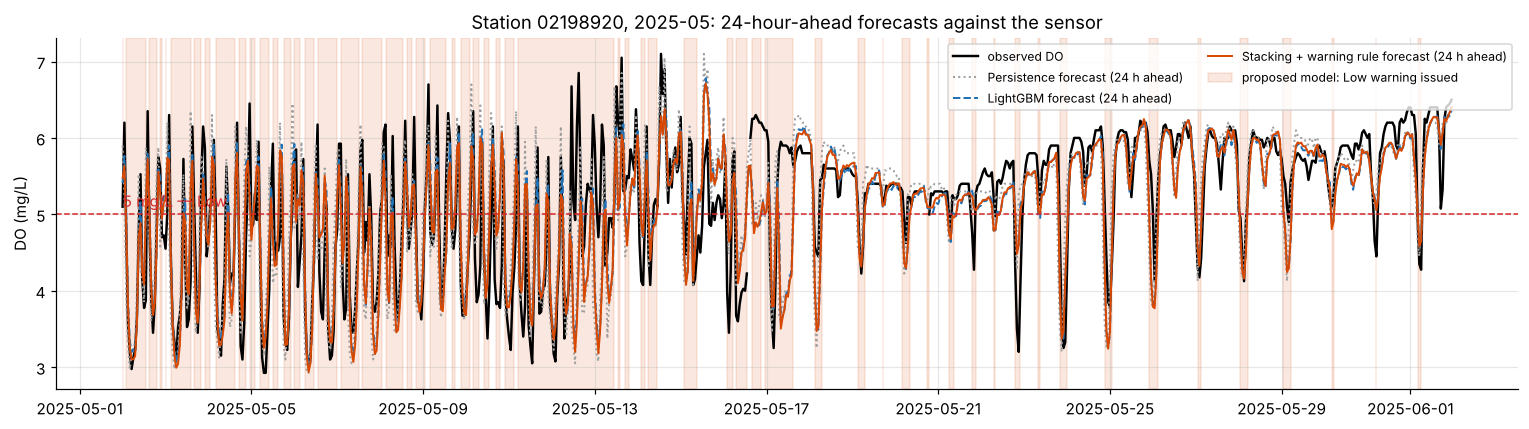

In [8]:
st, month = "02198920", "2025-05"
fig, ax = plt.subplots(figsize=(14, 4))
base = PRED[("persistence", 24)]
sel = (base["station"] == st) & (base["time"].dt.strftime("%Y-%m") == month)
t = base.loc[sel, "time"] + pd.Timedelta(hours=24)        # the hour being forecast
ax.plot(t, base.loc[sel, "y_true_reg"], color="black", lw=1.6, label="observed DO")
for m, ls in [("persistence", ":"), ("lightgbm", "--"), ("stacking", "-")]:
    ax.plot(t, PRED[(m, 24)].loc[sel, "pred_reg"], ls, color=COLOR[m], lw=1.3, label=f"{NAME[m]} forecast (24 h ahead)")
warn = PRED[("stacking", 24)].loc[sel, "pred_warn"].to_numpy() == 0
ax.fill_between(t, 0, 1, where=warn, transform=ax.get_xaxis_transform(), color="#d94801", alpha=.12,
                label="proposed model: Low warning issued")
ax.axhline(LOW, color="#d62728", lw=1, ls="--"); ax.text(t.iloc[0], LOW + .1, "5 mg/L — Low", color="#d62728")
ax.set_ylabel("DO (mg/L)"); ax.set_title(f"Station {st}, {month}: 24-hour-ahead forecasts against the sensor")
ax.legend(fontsize=8, loc="upper right", ncol=2)
plt.tight_layout(); plt.savefig(FIG_DIR / "nb1_example_station.png", bbox_inches="tight"); plt.show()

## 5. Classification comparison — Low / Medium / Good

Each model is scored two ways:
* **argmax** — the most likely class (how a classifier is normally used);
* **warning rule** — Low whenever P(Low) ≥ τ, with τ frozen from 2024 (part of the proposed system; applied to every model here for a fair comparison).

In [9]:
cls_rows = []
for h in HORIZONS:
    for m in METHODS:
        d = PRED[(m, h)]
        proba = d[[f"proba_{c}" for c in CLASS_NAMES]].to_numpy() if "proba_Low" in d else None
        for rule, col in [("argmax", "pred_argmax"), ("warning rule", "pred_warn")]:
            c = classification_metrics(d["y_true_cls"], d[col], proba)
            e = early_warning_metrics(d["class_now"], d["y_true_cls"], d[col])
            cls_rows.append({"key": m, "model": NAME[m], "horizon": h, "rule": rule,
                             **{k: v for k, v in c.items() if k != "confusion_matrix"}, **e,
                             "cm": c["confusion_matrix"]})
CLS = pd.DataFrame(cls_rows)

ccols = ["accuracy", "balanced_accuracy", "precision_macro", "recall_macro", "f1_macro",
         "roc_auc_ovr_macro", "recall_Low", "onset_recall", "false_alarm_rate"]
for rule in ["warning rule", "argmax"]:
    t = CLS[(CLS.horizon == 24) & (CLS.rule == rule)].set_index("model")[ccols]
    display(Markdown(f"### Classification, 24 h ahead, 2025 — **{rule}**"))
    display(t.style.format("{:.4f}", na_rep="–")
            .highlight_max(subset=ccols[:-1], color="#ffd8b1")
            .highlight_min(subset=["false_alarm_rate"], color="#e5f5e0"))

### Classification, 24 h ahead, 2025 — **warning rule**

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro,recall_Low,onset_recall,false_alarm_rate
model,,,,,,,,,
Persistence,0.9007,0.8806,0.8806,0.8806,0.8806,–,0.8859,0.0000,0.0000
Linear / Logistic Reg.,0.8872,0.8853,0.8624,0.8853,0.8722,0.9727,0.9182,0.3712,0.0125
Random Forest,0.9057,0.8955,0.8808,0.8955,0.8875,0.9815,0.9362,0.4501,0.0131
XGBoost,0.9046,0.8955,0.8789,0.8955,0.8864,0.9821,0.9409,0.4998,0.0156
LightGBM,0.9047,0.8959,0.8793,0.8959,0.8869,0.9823,0.9399,0.4991,0.0156
BiLSTM,0.8963,0.8879,0.8723,0.8879,0.8795,0.9783,0.9136,0.4241,0.0132
CNN-LSTM,0.8936,0.8873,0.8654,0.8873,0.8753,0.9791,0.9354,0.5221,0.0200
Simple average of 5,0.9034,0.8956,0.8772,0.8956,0.8855,0.9822,0.9428,0.5152,0.0161
Stacking + warning rule,0.9039,0.8960,0.8778,0.8960,0.8860,0.9815,0.9409,0.4958,0.0150


### Classification, 24 h ahead, 2025 — **argmax**

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro,recall_Low,onset_recall,false_alarm_rate
model,,,,,,,,,
Persistence,0.9007,0.8806,0.8806,0.8806,0.8806,–,0.8859,0.0000,0.0000
Linear / Logistic Reg.,0.8883,0.8860,0.8657,0.8860,0.8741,0.9727,0.9071,0.3123,0.0092
Random Forest,0.9088,0.8975,0.8886,0.8975,0.8928,0.9815,0.9058,0.2505,0.0039
XGBoost,0.9088,0.8986,0.8890,0.8986,0.8934,0.9821,0.9054,0.2992,0.0053
LightGBM,0.9088,0.8990,0.8891,0.8990,0.8936,0.9823,0.9065,0.3245,0.0059
BiLSTM,0.8971,0.8876,0.8759,0.8876,0.8810,0.9783,0.8950,0.3481,0.0093
CNN-LSTM,0.8967,0.8902,0.8721,0.8902,0.8804,0.9791,0.9176,0.4217,0.0130
Simple average of 5,0.9078,0.8992,0.8874,0.8992,0.8928,0.9822,0.9099,0.3176,0.0057
Stacking + warning rule,0.9081,0.8993,0.8877,0.8993,0.8930,0.9815,0.9084,0.2846,0.0046


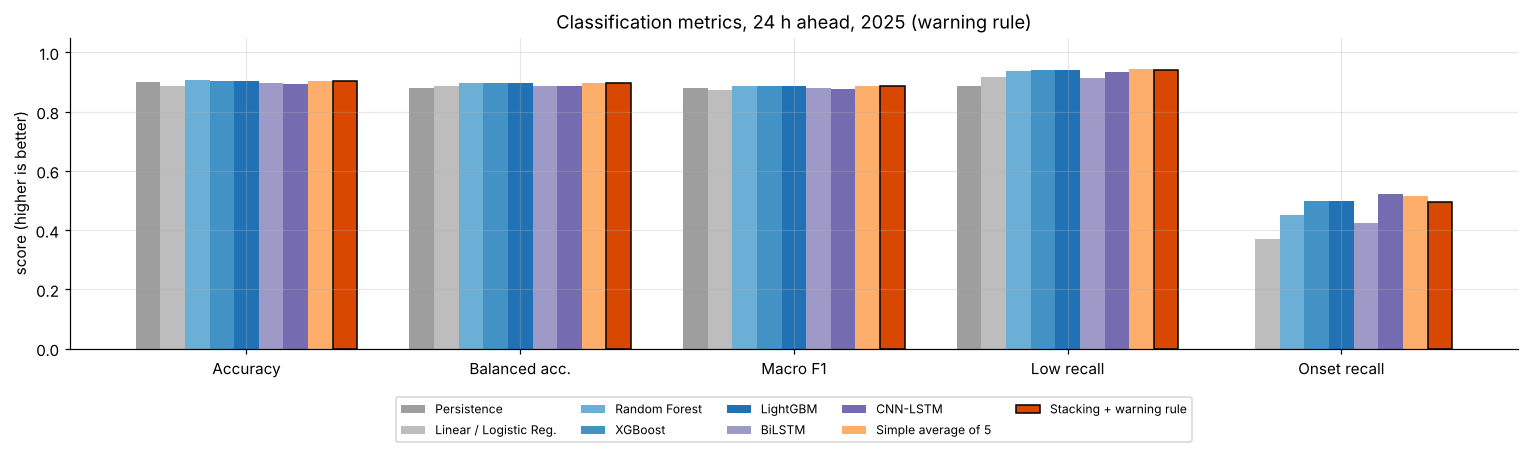

In [10]:
d = CLS[(CLS.horizon == 24) & (CLS.rule == "warning rule")].set_index("key")
show = ["accuracy", "balanced_accuracy", "f1_macro", "recall_Low", "onset_recall"]
labels = ["Accuracy", "Balanced acc.", "Macro F1", "Low recall", "Onset recall"]
fig, ax = plt.subplots(figsize=(14, 4.4))
w = .09
for i, m in enumerate(METHODS):
    ax.bar(np.arange(len(show)) + (i - 4) * w, d.loc[m, show], w, color=COLOR[m], label=NAME[m],
           edgecolor="black" if m == PROPOSED else "none")
ax.set_xticks(range(len(show))); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.05); ax.set_ylabel("score (higher is better)")
ax.set_title("Classification metrics, 24 h ahead, 2025 (warning rule)")
ax.legend(fontsize=8, ncol=5, loc="lower center", bbox_to_anchor=(.5, -.32))
plt.tight_layout(); plt.savefig(FIG_DIR / "nb1_classification_bars.png", bbox_inches="tight"); plt.show()

## 6. Existing model vs proposed model — head to head

The table puts the existing approaches next to the proposed system on the metrics that matter, at 24 h.
Existing models are scored the way they are normally used (argmax); the proposed system uses its warning rule.

In [11]:
def row(key, rule):
    r = REG[(REG.key == key) & (REG.horizon == 24)].iloc[0]
    c = CLS[(CLS.key == key) & (CLS.horizon == 24) & (CLS.rule == rule)].iloc[0]
    return {"R²": r.r2, "RMSE (mg/L)": r.rmse, "MAE (mg/L)": r.mae, "Accuracy": c.accuracy,
            "Macro F1": c.f1_macro, "ROC-AUC": c.roc_auc_ovr_macro, "Low recall": c.recall_Low,
            "Onset recall": c.onset_recall, "False-alarm rate": c.false_alarm_rate}

H2H = pd.DataFrame({
    "Existing: Persistence": row("persistence", "argmax"),
    "Existing: Linear/Logistic": row("linear", "argmax"),
    "Existing: LightGBM (best single)": row("lightgbm", "argmax"),
    "PROPOSED: Stacking + warning rule": row("stacking", "warning rule"),
}).T
display(H2H.style.format("{:.4f}", na_rep="–").apply(
    lambda s: ["background-color:#ffd8b1;font-weight:bold" if "PROPOSED" in s.name else "" for _ in s], axis=1))

p, b, n = H2H.loc["PROPOSED: Stacking + warning rule"], H2H.loc["Existing: LightGBM (best single)"], H2H.loc["Existing: Persistence"]
display(Markdown(f'''
**Improvement of the proposed model, 24 h ahead, on the unseen 2025 year:**

| vs | RMSE | Onset recall (safe → Low caught) | Low recall |
|---|---|---|---|
| Persistence | **{(1 - p["RMSE (mg/L)"] / n["RMSE (mg/L)"]) * 100:.1f} % lower** | **{n["Onset recall"]:.3f} → {p["Onset recall"]:.3f}** | {n["Low recall"]:.3f} → {p["Low recall"]:.3f} |
| LightGBM (best existing) | **{(1 - p["RMSE (mg/L)"] / b["RMSE (mg/L)"]) * 100:.1f} % lower** | **{b["Onset recall"]:.3f} → {p["Onset recall"]:.3f}** (×{p["Onset recall"] / b["Onset recall"]:.2f}) | {b["Low recall"]:.3f} → {p["Low recall"]:.3f} |

False-alarm rate of the proposed system: **{p["False-alarm rate"] * 100:.2f} %** (promise ≤ 2 %).
'''))

,R²,RMSE (mg/L),MAE (mg/L),Accuracy,Macro F1,ROC-AUC,Low recall,Onset recall,False-alarm rate
Existing: Persistence,0.9375,0.7553,0.4569,0.9007,0.8806,–,0.8859,0.0000,0.0000
Existing: Linear/Logistic,0.9471,0.6950,0.4294,0.8883,0.8741,0.9727,0.9071,0.3123,0.0092
Existing: LightGBM (best single),0.9490,0.6822,0.4158,0.9088,0.8936,0.9823,0.9065,0.3245,0.0059
PROPOSED: Stacking + warning rule,0.9505,0.6718,0.4074,0.9039,0.8860,0.9815,0.9409,0.4958,0.0150



**Improvement of the proposed model, 24 h ahead, on the unseen 2025 year:**

| vs | RMSE | Onset recall (safe → Low caught) | Low recall |
|---|---|---|---|
| Persistence | **11.1 % lower** | **0.000 → 0.496** | 0.886 → 0.941 |
| LightGBM (best existing) | **1.5 % lower** | **0.324 → 0.496** (×1.53) | 0.907 → 0.941 |

False-alarm rate of the proposed system: **1.50 %** (promise ≤ 2 %).


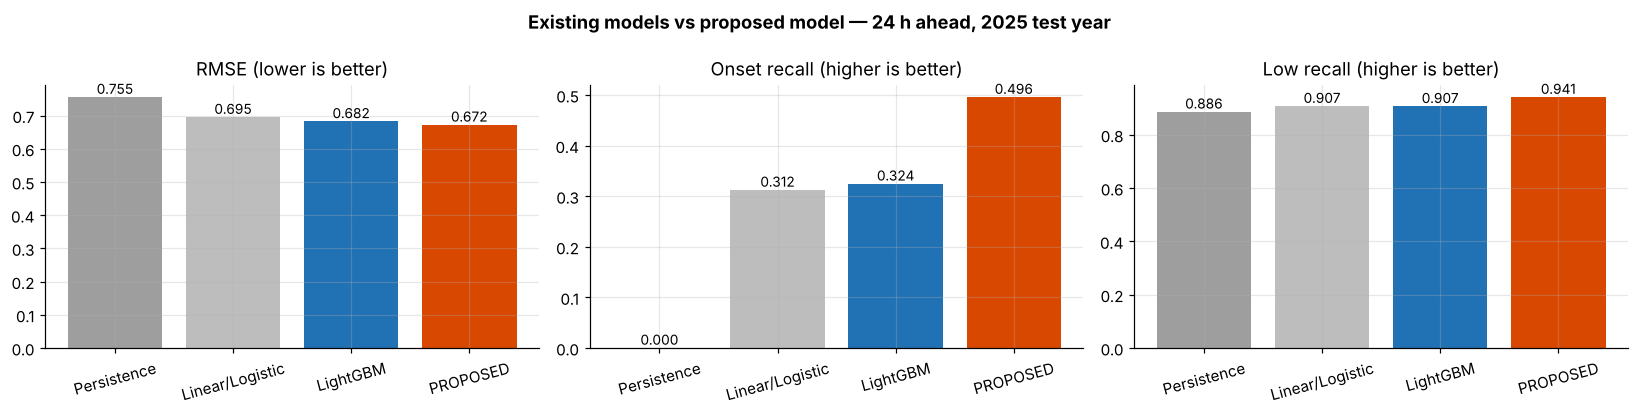

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
names = ["Persistence", "Linear/Logistic", "LightGBM", "PROPOSED"]
colors = [COLOR["persistence"], COLOR["linear"], COLOR["lightgbm"], COLOR["stacking"]]
for ax, metric, title in zip(axes, ["RMSE (mg/L)", "Onset recall", "Low recall"],
                             ["RMSE (lower is better)", "Onset recall (higher is better)", "Low recall (higher is better)"]):
    vals = H2H[metric].to_numpy()
    ax.bar(names, vals, color=colors)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(title); ax.tick_params(axis="x", rotation=15)
fig.suptitle("Existing models vs proposed model — 24 h ahead, 2025 test year", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "nb1_existing_vs_proposed.png", bbox_inches="tight"); plt.show()

> **A note on plain accuracy.** The proposed system's accuracy (0.904) and macro F1 (0.886) are about half a point below
> LightGBM's argmax (0.909 / 0.894). That is deliberate: the warning rule labels an hour *Low* as soon as the risk is high
> enough to act on, which turns some borderline Medium hours into warnings. In exchange it catches **half of all
> "safe now → Low in 24 h" hours instead of a third**, with false alarms still under the 2 % promise. For an early-warning
> system a missed onset costs far more than an extra alert. With argmax, the stacking ensemble has the same accuracy as
> LightGBM (0.908) and lower error — see the next table.

### Where the improvement comes from (component analysis)

The proposed system has two parts: the stacking combiner and the warning rule. Adding them one at a time shows
what each is worth:

In [13]:
steps = [("1. Best single model, argmax", "lightgbm", "argmax"),
         ("2. Simple average of 5, argmax", "simple_average", "argmax"),
         ("3. Stacking of 5, argmax", "stacking", "argmax"),
         ("4. Stacking of 5 + warning rule (PROPOSED)", "stacking", "warning rule")]
comp = pd.DataFrame({lbl: row(k, r) for lbl, k, r in steps}).T[
    ["RMSE (mg/L)", "Macro F1", "Low recall", "Onset recall", "False-alarm rate"]]
display(comp.style.format("{:.4f}"))
print("Reading: stacking gives the lowest error (RMSE); the warning rule is what lifts onset recall —\n"
      "the share of 'safe now, dangerous in 24 h' hours that get a warning — at a small, bounded cost in false alarms.")

,RMSE (mg/L),Macro F1,Low recall,Onset recall,False-alarm rate
"1. Best single model, argmax",0.6822,0.8936,0.9065,0.3245,0.0059
"2. Simple average of 5, argmax",0.6737,0.8928,0.9099,0.3176,0.0057
"3. Stacking of 5, argmax",0.6718,0.8930,0.9084,0.2846,0.0046
4. Stacking of 5 + warning rule (PROPOSED),0.6718,0.8860,0.9409,0.4958,0.0150


Reading: stacking gives the lowest error (RMSE); the warning rule is what lifts onset recall —
the share of 'safe now, dangerous in 24 h' hours that get a warning — at a small, bounded cost in false alarms.


## 7. Confusion matrices and ROC curves

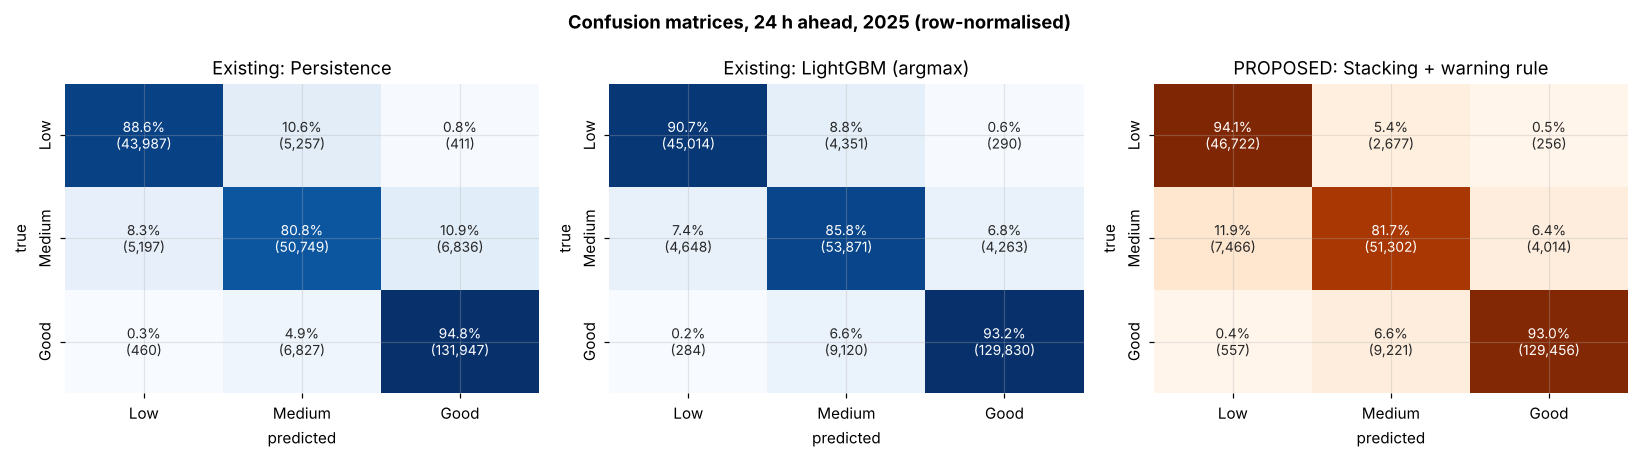

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (key, rule, title) in zip(axes, [("persistence", "argmax", "Existing: Persistence"),
                                         ("lightgbm", "argmax", "Existing: LightGBM (argmax)"),
                                         ("stacking", "warning rule", "PROPOSED: Stacking + warning rule")]):
    cm = CLS[(CLS.key == key) & (CLS.horizon == 24) & (CLS.rule == rule)].iloc[0]["cm"]
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    sns.heatmap(pct, annot=np.array([[f"{p:.1f}%\n({v:,})" for p, v in zip(pr, vr)] for pr, vr in zip(pct, cm)]),
                fmt="", cmap="Oranges" if key == "stacking" else "Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"fontsize": 9})
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
fig.suptitle("Confusion matrices, 24 h ahead, 2025 (row-normalised)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "nb1_confusion_matrices.png", bbox_inches="tight"); plt.show()

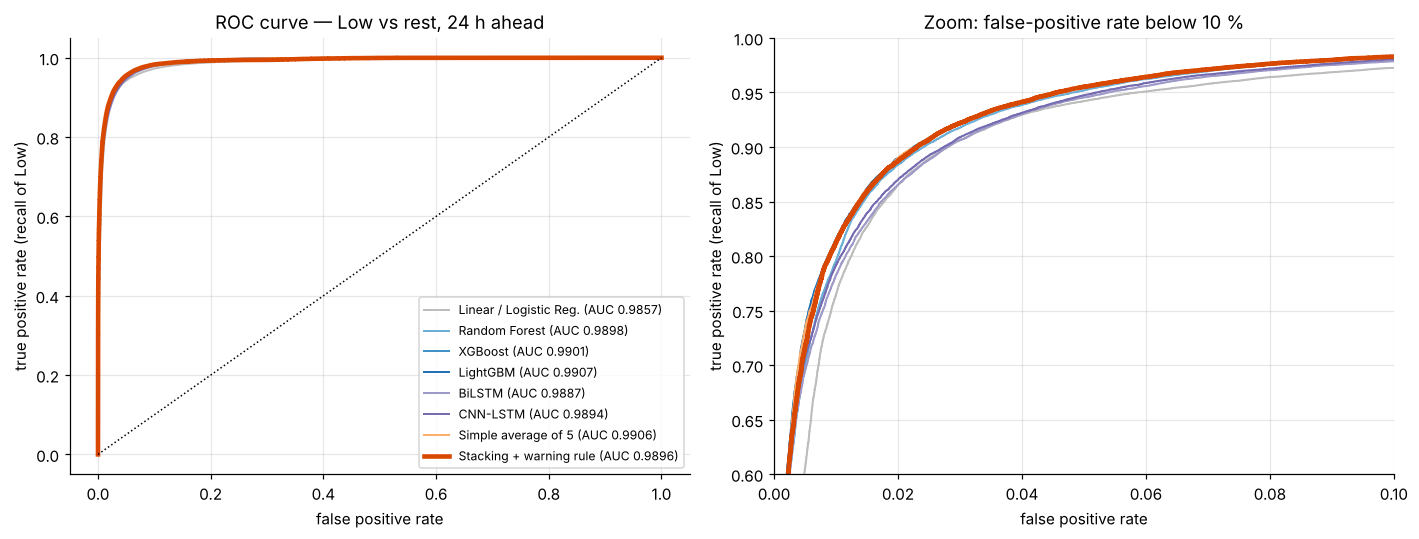

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for m in METHODS:
    d = PRED[(m, 24)]
    if "proba_Low" not in d:
        continue
    ok = d["y_true_cls"].notna()
    y = (d.loc[ok, "y_true_cls"].astype(int) == 0).astype(int)
    fpr, tpr, _ = roc_curve(y, d.loc[ok, "proba_Low"])
    lw = 3 if m == PROPOSED else 1.3
    for ax in axes:
        ax.plot(fpr, tpr, color=COLOR[m], lw=lw, label=f"{NAME[m]} (AUC {auc(fpr, tpr):.4f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_title("ROC curve — Low vs rest, 24 h ahead")
axes[1].set_xlim(0, .1); axes[1].set_ylim(.6, 1); axes[1].set_title("Zoom: false-positive rate below 10 %")
for ax in axes:
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate (recall of Low)")
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "nb1_roc_low.png", bbox_inches="tight"); plt.show()

## 8. Statistical significance — is the proposed model *really* better?

Single-number differences can be noise. The project resampled the 2025 rows **1,000 times by station-week blocks**
(keeping the time structure intact) and computed a 95 % confidence interval for each difference.
A difference is significant when its interval does not contain zero.

In [16]:
boot = pd.read_csv(TEST_DIR / "bootstrap.csv")
boot = boot[boot["comparison"] != "rule"]          # the rule-vs-argmax rows are shown in section 9
boot["comparison"] = boot["comparison"].map({"vs_persistence": "Proposed vs Persistence",
                                             "vs_best_single": "Proposed vs best single model"}).fillna(boot["comparison"])
boot["95% CI"] = boot.apply(lambda r: f"[{r.lo:+.4f}, {r.hi:+.4f}]", axis=1)
boot["verdict"] = np.where(boot["significant"],
                           np.where(((boot.metric == "rmse") & (boot["mean"] < 0)) |
                                    ((boot.metric != "rmse") & (boot["mean"] > 0)), "proposed significantly better",
                                    "proposed significantly worse"), "no significant difference")
display(boot[["comparison", "horizon", "metric", "mean", "95% CI", "verdict"]]
        .rename(columns={"mean": "difference"}).style.format({"difference": "{:+.4f}"}).hide(axis="index")
        .apply(lambda s: ["color:#2ca02c;font-weight:bold" if "better" in v else "" for v in s], subset=["verdict"]))
print("Negative RMSE difference = proposed has lower error. Positive F1 / onset-recall difference = proposed better.")

comparison,horizon,metric,difference,95% CI,verdict
Proposed vs Persistence,6,rmse,-0.8301,"[-0.8829, -0.7813]",proposed significantly better
Proposed vs Persistence,6,f1_macro,+0.1536,"[+0.1423, +0.1658]",proposed significantly better
Proposed vs Persistence,6,onset_recall,+0.8607,"[+0.8431, +0.8778]",proposed significantly better
Proposed vs Persistence,12,rmse,-0.9421,"[-1.0070, -0.8743]",proposed significantly better
Proposed vs Persistence,12,f1_macro,+0.1589,"[+0.1451, +0.1720]",proposed significantly better
Proposed vs Persistence,12,onset_recall,+0.8603,"[+0.8383, +0.8788]",proposed significantly better
Proposed vs Persistence,24,rmse,-0.0836,"[-0.0949, -0.0700]",proposed significantly better
Proposed vs Persistence,24,f1_macro,+0.0055,"[+0.0027, +0.0079]",proposed significantly better
Proposed vs Persistence,24,onset_recall,+0.4962,"[+0.4610, +0.5298]",proposed significantly better
Proposed vs Persistence,48,rmse,-0.1537,"[-0.1705, -0.1359]",proposed significantly better


Negative RMSE difference = proposed has lower error. Positive F1 / onset-recall difference = proposed better.


## 9. Early-warning performance

### 9a. Onset recall vs false alarms — the warning rule

Sweeping the threshold τ shows the trade-off between catching onsets and raising false alarms.
The black marker is the τ that was **frozen from 2024** before the test — not tuned on 2025.

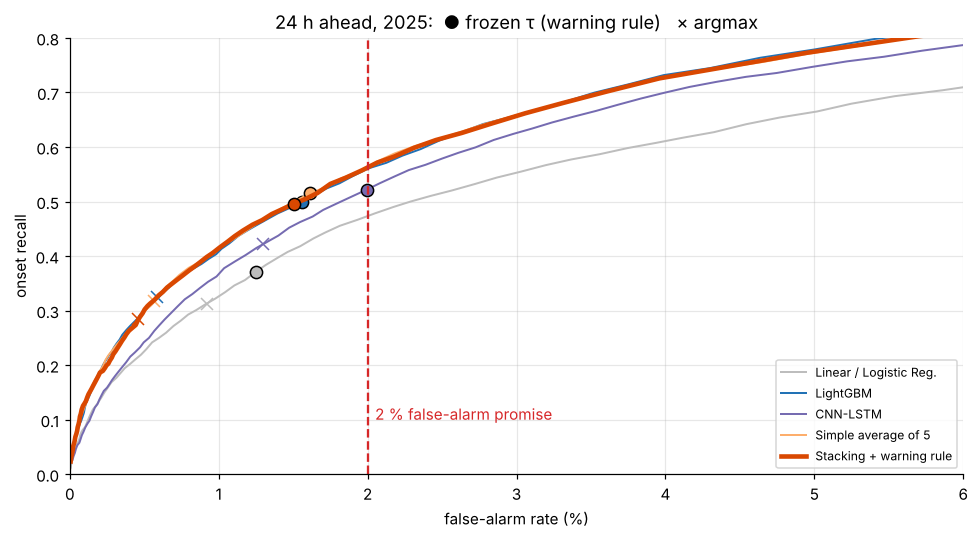

,τ (frozen),onset recall — argmax,onset recall — rule,false alarm — argmax,false alarm — rule
horizon (h),,,,,
6,0.270,0.800,0.861,0.010,0.018
12,0.240,0.795,0.861,0.010,0.017
24,0.240,0.285,0.496,0.005,0.015
48,0.350,0.380,0.485,0.007,0.013


In [17]:
with open(ROOT / CFG["final_test"]["thresholds_file"]) as f:
    TAU = json.load(f)

def apply_rule(proba, tau):
    pred = 1 + proba[:, 1:].argmax(axis=1)      # best of Medium / Good ...
    pred[proba[:, 0] >= tau] = 0                 # ... unless P(Low) >= tau
    return pred

fig, ax = plt.subplots(figsize=(9, 5))
for m in ["linear", "lightgbm", "cnn_lstm", "simple_average", "stacking"]:
    d = PRED[(m, 24)]
    proba = d[[f"proba_{c}" for c in CLASS_NAMES]].to_numpy()
    pts = []
    for tau in np.arange(.05, .95, .01):
        e = early_warning_metrics(d["class_now"], d["y_true_cls"], apply_rule(proba, tau))
        pts.append((e["false_alarm_rate"] * 100, e["onset_recall"]))
    pts = np.array(pts)
    ax.plot(pts[:, 0], pts[:, 1], color=COLOR[m], lw=3 if m == PROPOSED else 1.3, label=NAME[m])
    e = CLS[(CLS.key == m) & (CLS.horizon == 24) & (CLS.rule == "warning rule")].iloc[0]
    ax.plot(e.false_alarm_rate * 100, e.onset_recall, "o", color=COLOR[m], mec="black", ms=8)
    a = CLS[(CLS.key == m) & (CLS.horizon == 24) & (CLS.rule == "argmax")].iloc[0]
    ax.plot(a.false_alarm_rate * 100, a.onset_recall, "x", color=COLOR[m], ms=8)
ax.axvline(2, color="#d62728", ls="--"); ax.text(2.05, .1, "2 % false-alarm promise", color="#d62728")
ax.set_xlim(0, 6); ax.set_ylim(0, .8)
ax.set_xlabel("false-alarm rate (%)"); ax.set_ylabel("onset recall")
ax.set_title("24 h ahead, 2025:  ● frozen τ (warning rule)   × argmax")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "nb1_onset_vs_false_alarm.png", bbox_inches="tight"); plt.show()

tab = []
for h in HORIZONS:
    a = CLS[(CLS.key == PROPOSED) & (CLS.horizon == h) & (CLS.rule == "argmax")].iloc[0]
    w = CLS[(CLS.key == PROPOSED) & (CLS.horizon == h) & (CLS.rule == "warning rule")].iloc[0]
    tab.append({"horizon (h)": h, "τ (frozen)": TAU[f"stacking_h{h}"]["tau"],
                "onset recall — argmax": a.onset_recall, "onset recall — rule": w.onset_recall,
                "false alarm — argmax": a.false_alarm_rate, "false alarm — rule": w.false_alarm_rate})
display(pd.DataFrame(tab).set_index("horizon (h)").style.format("{:.3f}"))

### 9b. Lead time — how much warning before a real low-DO event?

An **event** starts when DO drops below 5 mg/L after at least 24 h above it. It counts as *warned* if the
24 h-ahead warning fired at any hour in the 24 h before the event began.

,value
low-DO events in 2025,230
warned in advance,119 (51.7%)
median lead time (h),20
mean lead time (h),14.6
stations with at least one event,30 of 30


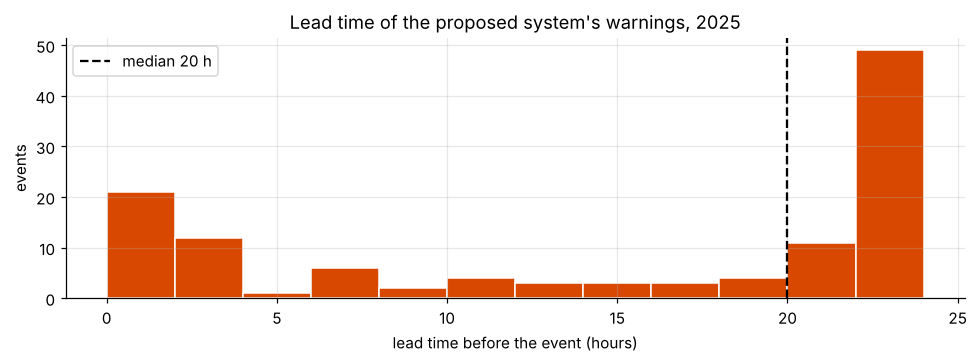

In [18]:
lead = pd.read_csv(TEST_DIR / "lead_times.csv")
warned = lead[lead["warned"]]
display(pd.DataFrame({"value": {
    "low-DO events in 2025": len(lead),
    "warned in advance": f"{len(warned)} ({len(warned) / len(lead):.1%})",
    "median lead time (h)": f"{warned['lead_hours'].median():.0f}",
    "mean lead time (h)": f"{warned['lead_hours'].mean():.1f}",
    "stations with at least one event": f"{lead['station'].nunique()} of 30"}}))

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(warned["lead_hours"], bins=np.arange(0, 25, 2), color=COLOR[PROPOSED], edgecolor="white")
ax.axvline(warned["lead_hours"].median(), color="black", ls="--", label=f"median {warned['lead_hours'].median():.0f} h")
ax.set_xlabel("lead time before the event (hours)"); ax.set_ylabel("events")
ax.set_title("Lead time of the proposed system's warnings, 2025"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "nb1_lead_time.png", bbox_inches="tight"); plt.show()

## 10. Multimodal ablation — what each data source contributes

LightGBM retrained on 2023 + 2024 with three input sets, scored on 2025:
**W** = water + time + station · **W+M** = + weather (meteorology) · **W+M+A** = + air quality.

,features,RMSE 6 h,RMSE 12 h,RMSE 24 h,RMSE 48 h,onset recall 6 h,onset recall 12 h,onset recall 24 h,onset recall 48 h
set,,,,,,,,,
W,156,0.5346,0.6176,0.7001,0.8954,0.8652,0.8589,0.4875,0.4400
W+M,195,0.5306,0.6043,0.6834,0.8736,0.8672,0.8559,0.4880,0.4522
W+M+A,211,0.5313,0.6035,0.6809,0.8722,0.8665,0.8610,0.4944,0.4614


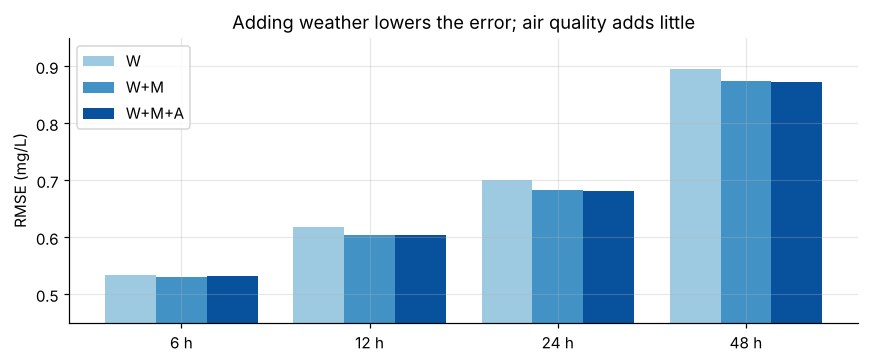

In [19]:
abl = pd.read_csv(TEST_DIR / "ablation.csv")
t = abl.pivot(index="set", columns="horizon", values="rmse").loc[["W", "W+M", "W+M+A"]]
t.columns = [f"RMSE {h} h" for h in t.columns]
t.insert(0, "features", abl.groupby("set")["n_features"].first())
o = abl.pivot(index="set", columns="horizon", values="onset_recall").loc[["W", "W+M", "W+M+A"]]
o.columns = [f"onset recall {h} h" for h in o.columns]
display(pd.concat([t, o], axis=1).style.format("{:.4f}", subset=list(t.columns[1:]) + list(o.columns)))

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(HORIZONS))
for i, (s, c) in enumerate([("W", "#9ecae1"), ("W+M", "#4292c6"), ("W+M+A", "#08519c")]):
    ax.bar(x + (i - 1) * .27, abl[abl.set == s].sort_values("horizon")["rmse"], .27, color=c, label=s)
ax.set_xticks(x); ax.set_xticklabels([f"{h} h" for h in HORIZONS]); ax.set_ylim(.45, .95)
ax.set_ylabel("RMSE (mg/L)"); ax.set_title("Adding weather lowers the error; air quality adds little")
ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "nb1_ablation.png", bbox_inches="tight"); plt.show()

### Why an ensemble of *different* model families helps

An ensemble gains most from members that make **different** mistakes. The correlation of the 24 h errors shows the
deep models (BiLSTM, CNN-LSTM) err differently from the trees — which is why they are kept even though, alone, they
are not the most accurate.

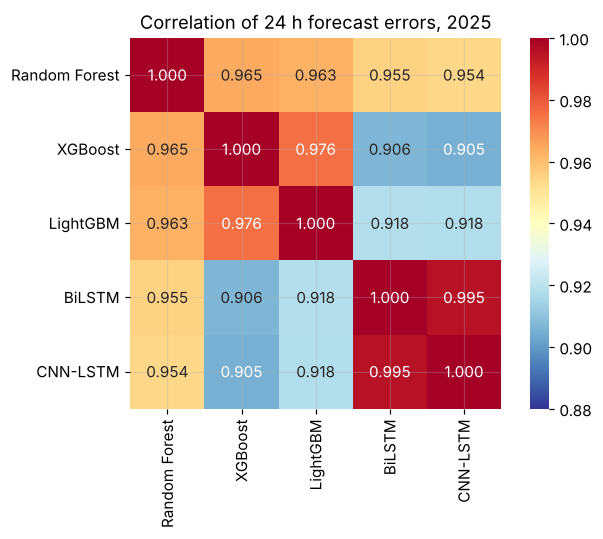

In [20]:
corr = pd.read_csv(TEST_DIR / "step10_error_correlation_h24.csv", index_col=0)
corr.index = corr.columns = [NAME[c] for c in corr.columns]
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="RdYlBu_r", vmin=.88, vmax=1, ax=ax, square=True)
ax.set_title("Correlation of 24 h forecast errors, 2025")
plt.tight_layout(); plt.savefig(FIG_DIR / "nb1_error_correlation.png", bbox_inches="tight"); plt.show()

## 11. Generalisation — a second unseen year (2026)

After the 2025 test, the five models were retrained on 2023–2025 with the same frozen settings and deployed.
They were then scored on **2026-01-01 → 2026-10-13**, a period none of them had seen, with the test plan committed
before any 2026 value was downloaded (`reports/plan_2026.md`).

In [21]:
wf = pd.read_csv(ROOT / "results" / "live_2026" / "walk_forward.csv")
wf = wf[wf["available"]][["train", "test", "horizon", "r2", "rmse", "f1_macro", "recall_Low",
                          "onset_recall", "false_alarm_rate", "note"]]
display(wf.style.format({c: "{:.4f}" for c in ["r2", "rmse", "f1_macro", "recall_Low", "onset_recall",
                                                  "false_alarm_rate"]}).hide(axis="index"))
print("The 2024 row is in-sample (it was the tuning year). 2025 and 2026 are genuine unseen-year tests.")

train,test,horizon,r2,rmse,f1_macro,recall_Low,onset_recall,false_alarm_rate,note
2023,2024,6,0.9684,0.5216,0.8931,0.9652,0.9039,0.0248,not clean: 2024 was the tuning year
2023,2024,12,0.9609,0.5806,0.8850,0.9637,0.8913,0.0249,not clean: 2024 was the tuning year
2023,2024,24,0.9508,0.6509,0.8761,0.9551,0.5941,0.0240,not clean: 2024 was the tuning year
2023,2024,48,0.9152,0.8532,0.8407,0.9233,0.5552,0.0246,not clean: 2024 was the tuning year
2023-2024,2025,6,0.9710,0.5144,0.9052,0.9493,0.8610,0.0175,the frozen result
2023-2024,2025,12,0.9621,0.5882,0.8972,0.9464,0.8608,0.0173,the frozen result
2023-2024,2025,24,0.9505,0.6718,0.8860,0.9409,0.4958,0.0150,the frozen result
2023-2024,2025,48,0.9202,0.8535,0.8562,0.9092,0.4853,0.0133,the frozen result
2023-2025,2026,6,0.9554,0.6172,0.8924,0.9386,0.8842,0.0186,"deployed models, pre-registered"
2023-2025,2026,12,0.9449,0.6863,0.8836,0.9364,0.8783,0.0202,"deployed models, pre-registered"


The 2024 row is in-sample (it was the tuning year). 2025 and 2026 are genuine unseen-year tests.


## 12. Conclusion

In [22]:
p = H2H.loc["PROPOSED: Stacking + warning rule"]
lead_med = warned["lead_hours"].median()
display(Markdown(f'''
**Result on the untouched 2025 test year, 24 hours ahead:**

| | Proposed system |
|---|---|
| R² | **{p["R²"]:.3f}** |
| RMSE | **{p["RMSE (mg/L)"]:.3f} mg/L** |
| Accuracy | **{p["Accuracy"]:.3f}** |
| Macro F1 | **{p["Macro F1"]:.3f}** |
| ROC-AUC | **{p["ROC-AUC"]:.3f}** |
| Low-class recall | **{p["Low recall"]:.3f}** |
| Onset recall | **{p["Onset recall"]:.3f}** |
| False-alarm rate | **{p["False-alarm rate"] * 100:.2f} %** (promise ≤ 2 %) |
| Events warned in advance | **{len(warned) / len(lead):.1%}**, median lead **{lead_med:.0f} h** |

1. **Every learned model beats persistence** at every horizon, and the proposed stacking ensemble has the **lowest RMSE
   at all four horizons** — significantly lower than the best single model (bootstrap 95 % CIs exclude zero).
2. **The warning rule is the largest single gain for early warning:** at 24 h it lifts onset recall from
   {CLS[(CLS.key == PROPOSED) & (CLS.horizon == 24) & (CLS.rule == "argmax")].iloc[0].onset_recall:.3f} to
   {p["Onset recall"]:.3f} while keeping false alarms inside the 2 % promise.
3. **Multimodal data helps:** weather lowers the error at every horizon; air quality adds little.
4. **Diversity matters:** the deep models make different errors from the trees, which is what an ensemble needs.
5. **The result generalises:** the deployed models, tested on an unseen 2026, keep false alarms near 2 % and catch
   a similar share of onsets.
'''))


**Result on the untouched 2025 test year, 24 hours ahead:**

| | Proposed system |
|---|---|
| R² | **0.951** |
| RMSE | **0.672 mg/L** |
| Accuracy | **0.904** |
| Macro F1 | **0.886** |
| ROC-AUC | **0.982** |
| Low-class recall | **0.941** |
| Onset recall | **0.496** |
| False-alarm rate | **1.50 %** (promise ≤ 2 %) |
| Events warned in advance | **51.7%**, median lead **20 h** |

1. **Every learned model beats persistence** at every horizon, and the proposed stacking ensemble has the **lowest RMSE
   at all four horizons** — significantly lower than the best single model (bootstrap 95 % CIs exclude zero).
2. **The warning rule is the largest single gain for early warning:** at 24 h it lifts onset recall from
   0.285 to
   0.496 while keeping false alarms inside the 2 % promise.
3. **Multimodal data helps:** weather lowers the error at every horizon; air quality adds little.
4. **Diversity matters:** the deep models make different errors from the trees, which is what an ensemble needs.
5. **The result generalises:** the deployed models, tested on an unseen 2026, keep false alarms near 2 % and catch
   a similar share of onsets.


*Figures from this notebook are saved in `results/notebook_figures/` for use in the presentation.*